# Task 3: Recognizing Handwritten Digits

In this task of the project we aim at building and training an artificial deep neural network that recognises and predicts handwritten numbers. We will build a feedforward neural-network that consists of functions to cover different aspects of building, training and testing phases. 

### What is a feedforward neural-network architecture?

Feedforward neural-network is a type of architecture design used in ANN. FNN is a specific type of artificial neural network where connections between the nodes do not form any type of cycle or in other words the information moves in one direction only: from the input layer to the hidden layers to the output layer. The structure of an FNN is acyclic, meaning you cannot start from one neuron and follow the connections to return to the same neuron.

##### Visually representation: `Input Layer` → `Hidden Layer 1` → `Output Layer`

### How we will structure the architecture of the FNN for recognising (predicting) handwritten digits from the MNIST dataset? 

#### Functions to structure our FNN: 

##### 1. Data Preparation 

`load_data():` Load the MNIST dataset.

`flatten_images():` Prepare the images for the model input by flattening them.

`split_target()`: Splitting the data into target and features

`split_train_test()` Splitting the data into training and testing

`subset_select()` Function to select an appropriate sample size for initial experimentation

##### 2. Initialization

`initialize_parameters(input_size, hidden_size, output_size):` Initialize the weights and biases.

- input_size = 784: Because the images in the MNIST dataset are 28x28 pixels and when we flatten them we get a 784 dimensional vector (28x28=784). 

- hidden_size = N: We want to optimise the number of hidden layers in order to have faster and better predictions. 

- output_size = 10: Because there are numbers from 0-9 and this makes 10 total classes for prediction. If we lower the output_size we will get a lot of wrong predictions.

##### 3. Forward Propagation: 

`relu(x):` Apply the ReLU activation function. The ReLU (Rectified Linear Unit) activation function is used to introduce non-linearity into the network. It is defined as: 

ReLU(x)=max(0,x)

We need the non-linearity in order for the neural network to learn more complex patterns in the data.

`softmax(x):` Apply the Softmax activation function. The Softmax activation function is used in the output layer of a classification network. It converts the raw output scores (logits) into probabilities that sum up to 1.

 Softmax ensures that the output values can be interpreted as probabilities.

`forward_propagation(X, W1, b1, W2, b2):` Computes the forward pass through the network, from input to output, using linear transformations and activation functions.

##### 4. Loss Calculation

`cross_entropy_loss(y_true, y_pred):` Calculate the cross-entropy loss between the true values and the predicted ones. 

##### 5. Backward Propagation 

`relu_derivative():` This function computes the derivatives of the ReLU function.

`apply_dropout(A, keep_prob):` Apply dropout to the activations during training.

`backward_propagation(X, Y, Z1, A1, Z2, A2, W1, W2):` Compute the backward pass where we optimise the weights and biases by going from the output to the input.

##### 6. Training Loop

`update_parameters(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate):` This function updates the weights and biases. 

`train_neural_network(X_train, Y_train, X_val, Y_val, hidden_size, learning_rate, epochs, batch_size)`: Train the network using forward and backward propagation.

`learning_rate_scheduler(epoch, initial_lr):` Adjust the learning rate as training progresses.

`hyperparameter_tuning(X_train, Y_train, X_val, Y_val):` Find optimal hyperparameters using grid search or random search.

##### 7. Evaluation 

`calculate_accuracy(y_true, y_pred):` Calculate the accuracy of the model.

`evaluate_model(X_test, y_test, W1, b1, W2, b2): `Evaluate the trained model on the test set.

### Our FNN architecture will consist of the following layers:

Input Layer (784 nodes) → Hidden Layer 1 (128 nodes) -- ReLU Activation → Output Layer (10 nodes)

***
# Load the data

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split

***
# Process the data into training, validation, and test sets

In [19]:
# Function to load the data
def load_data():
    (X_train, y_train), (X_test, y_test) = mnist.load_data()
    return X_train, y_train, X_test, y_test

# Function to Flatten the images
def flatten_images(X_train, X_test):
    X_train = X_train.reshape(X_train.shape[0], -1) # Flatten the images
    X_test = X_test.reshape(X_test.shape[0], -1) # Flatten the images
    return X_train, X_test # Return the flattened images

# Function to One-hot encode the labels
def one_hot_encode(y, num_classes):  # One-hot encode the labels
    return np.eye(num_classes)[y] # Return the one-hot encoded labels

# Function to Normalize the data between 0 and 1 by dividing by 255
def normalize_data(X_train, X_val, X_test): # Normalize the data
    X_train = X_train / 255.0 # Normalize the data
    X_val = X_val / 255.0 # Normalize the data
    X_test = X_test / 255.0 # Normalize the data 
    return X_train, X_val, X_test # Return the normalized data

# Function to Split the data into training and validation sets
def split_data(X_train, y_train, validation_size=0.1667):
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=validation_size, random_state=42)
    return X_train, y_train, X_val, y_val

In [20]:
# Load the data
X_train, y_train, X_test, y_test = load_data()

# Flatten the images
X_train, X_test = flatten_images(X_train, X_test)

# One-hot encode the labels
y_train = one_hot_encode(y_train, 10)
y_test = one_hot_encode(y_test, 10)

# Split the training data into training and validation sets using sklearn
X_train, y_train, X_val, y_val = split_data(X_train, y_train)

# Normalize the data
X_train, X_val, X_test = normalize_data(X_train, X_val, X_test)

# Check the shapes to ensure everything is correct
print(f"Training set shape: {X_train.shape}, {y_train.shape}")
print(f"Validation set shape: {X_val.shape}, {y_val.shape}")
print(f"Test set shape: {X_test.shape}, {y_test.shape}")

Training set shape: (49998, 784), (49998, 10)
Validation set shape: (10002, 784), (10002, 10)
Test set shape: (10000, 784), (10000, 10)


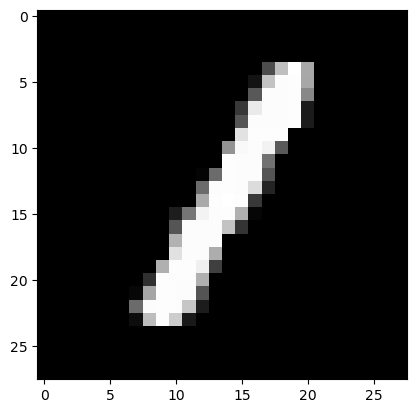

In [21]:
# Display a sample image
plt.imshow(X_train[0].reshape(28, 28), cmap='gray')

***
# Define the Neural Network

In [22]:
# Function to initialize the parameters
def initialize_parameters(input_size, hidden_size, output_size):
    W1 = np.random.randn(hidden_size, input_size) * 0.01 # Initialize the first set of weights
    b1 = np.zeros((hidden_size, 1)) # Initialize the first set of biases
    W2 = np.random.randn(output_size, hidden_size) * 0.01 # Initialize the second set of weights
    b2 = np.zeros((output_size, 1)) # Initialize the second set of biases
    return W1, b1, W2, b2

# Define the activation functions
def relu(x): 
    return np.maximum(0, x) # ReLU activation function

# Define the derivative of the ReLU activation function
def relu_derivative(x):
    return np.where(x <= 0, 0, 1) # Derivative of the ReLU activation function

# Define the softmax activation function for the output layer
def softmax(x):
    exps = np.exp(x - np.max(x, axis=0, keepdims=True)) # Subtract the maximum value to prevent overflow
    return exps / np.sum(exps, axis=0, keepdims=True) # Softmax activation function

# Define the forward propagation step to compute the output of the neural network
def forward_propagation(X, W1, b1, W2, b2, keep_prob=0.8): # Forward propagation
    Z1 = np.dot(W1, X) + b1  # Compute the weighted sum of the inputs
    A1 = relu(Z1) # Apply the ReLU activation function
    D1 = np.random.rand(A1.shape[0], A1.shape[1]) < keep_prob # Dropout mask
    A1 = np.multiply(A1, D1) # Apply dropout
    A1 /= keep_prob # Scale the activations
    Z2 = np.dot(W2, A1) + b2 # Compute the weighted sum of the hidden layer
    A2 = softmax(Z2) # Apply the softmax activation function
    return Z1, A1, Z2, A2, D1 # Return the intermediate outputs

# Define the cross-entropy loss function 
def cross_entropy_loss(y_true, y_pred, W1, W2, lambda_reg): 
    m = y_true.shape[1] # Number of samples
    log_likelihood = -np.log(y_pred[y_true.argmax(axis=0), range(m)] + 1e-8) # Compute the log-likelihood
    loss = np.sum(log_likelihood) / m # Compute the loss
    reg_loss = (lambda_reg / (2 * m)) * (np.sum(np.square(W1)) + np.sum(np.square(W2))) # Regularization loss
    return loss + reg_loss

# Define the backward propagation step to compute the gradients of the loss function with respect to the parameters
def backward_propagation(X, Y, Z1, A1, Z2, A2, W1, W2, D1, keep_prob=0.8):
    m = X.shape[1] # Number of samples
    dZ2 = A2 - Y # Compute the gradient of the loss with respect to Z2
    dW2 = (1 / m) * np.dot(dZ2, A1.T) # Compute the gradient of the loss with respect to W2
    db2 = (1 / m) * np.sum(dZ2, axis=1, keepdims=True) # Compute the gradient of the loss with respect to b2
    dA1 = np.dot(W2.T, dZ2) # Compute the gradient of the loss with respect to A1
    dA1 = np.multiply(dA1, D1) # Apply dropout
    dA1 /= keep_prob # Scale the activations
    dZ1 = dA1 * relu_derivative(Z1) # Compute the gradient of the loss with respect to Z1
    dW1 = (1 / m) * np.dot(dZ1, X.T) # Compute the gradient of the loss with respect to W1
    db1 = (1 / m) * np.sum(dZ1, axis=1, keepdims=True) # Compute the gradient of the loss with respect to b1
    return dW1, db1, dW2, db2

# Define the function to update the parameters 
def update_parameters(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate):
    W1 -= learning_rate * dW1 # Update the first set of weights
    b1 -= learning_rate * db1 # Update the first set of biases
    W2 -= learning_rate * dW2 # Update the second set of weights
    b2 -= learning_rate * db2 # Update the second set of biases
    return W1, b1, W2, b2

# Define the function to train the neural network
def train_neural_network(X_train, y_train, X_val, y_val, hidden_size, learning_rate, epochs, batch_size, lambda_reg, keep_prob, patience=10): # Train the neural network
    input_size = X_train.shape[1] # Input size
    output_size = y_train.shape[1] # Output size
    W1, b1, W2, b2 = initialize_parameters(input_size, hidden_size, output_size) # Initialize the parameters
    best_val_loss = float('inf') # Initialize the best validation loss
    patience_counter = 0 # Initialize the patience counter
    
    # Train the neural network
    for epoch in range(epochs):
        permutation = np.random.permutation(X_train.shape[0]) # Shuffle the training data
        X_train_shuffled = X_train[permutation] # Shuffle the training data
        y_train_shuffled = y_train[permutation] # Shuffle the training data
        
        # Loop over the training data in batches
        for i in range(0, X_train.shape[0], batch_size): # Loop over the training data
            X_batch = X_train_shuffled[i:i + batch_size].T # Get a batch of inputs
            Y_batch = y_train_shuffled[i:i + batch_size].T # Get a batch of outputs
            
            # Perform forward and backward propagation
            Z1, A1, Z2, A2, D1 = forward_propagation(X_batch, W1, b1, W2, b2, keep_prob) # Forward propagation
            dW1, db1, dW2, db2 = backward_propagation(X_batch, Y_batch, Z1, A1, Z2, A2, W1, W2, D1, keep_prob)
            W1, b1, W2, b2 = update_parameters(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate)
        
        # Compute the validation loss
        Z1, A1, Z2, A2, _ = forward_propagation(X_val.T, W1, b1, W2, b2)
        val_loss = cross_entropy_loss(y_val.T, A2, W1, W2, lambda_reg)
        
        # Print the validation loss every 10 epochs
        if epoch % 10 == 0:
            print(f"Epoch {epoch}, Val Loss: {val_loss}")
        
        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
        else:
            patience_counter += 1
        
        # Break out of the loop if the validation loss does not improve for 'patience' epochs
        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch}")
            break
    
    return W1, b1, W2, b2

# Define the function to evaluate the model on the test set
def evaluate_model(X_test, y_test, W1, b1, W2, b2):
    _, _, _, A2, _ = forward_propagation(X_test.T, W1, b1, W2, b2, keep_prob=1.0)  # No dropout during evaluation
    predictions = np.argmax(A2, axis=0)
    labels = np.argmax(y_test.T, axis=0)
    accuracy = np.mean(predictions == labels)
    return accuracy

In [23]:
# Train the neural network
W1, b1, W2, b2 = train_neural_network(
    X_train, y_train, X_val, y_val,
    hidden_size=124, learning_rate=0.04, epochs=150, batch_size=64,
    lambda_reg=0.01, keep_prob=0.8, patience=10
)

# Evaluate the model on the validation set
val_accuracy = evaluate_model(X_val, y_val, W1, b1, W2, b2)
print(f"Validation Accuracy: {val_accuracy}")

Epoch 0, Val Loss: 0.4599634122970473
Epoch 10, Val Loss: 0.16400982349670964
Epoch 20, Val Loss: 0.12688938074476175
Epoch 30, Val Loss: 0.11020815585776855
Epoch 40, Val Loss: 0.09916981653773868
Epoch 50, Val Loss: 0.09062806135912138
Epoch 60, Val Loss: 0.09065712026201861
Epoch 70, Val Loss: 0.08660118139324671
Epoch 80, Val Loss: 0.09269151290937667
Epoch 90, Val Loss: 0.09021174204551391
Early stopping at epoch 99
Validation Accuracy: 0.9802039592081584


***
# Post-training Evaluation

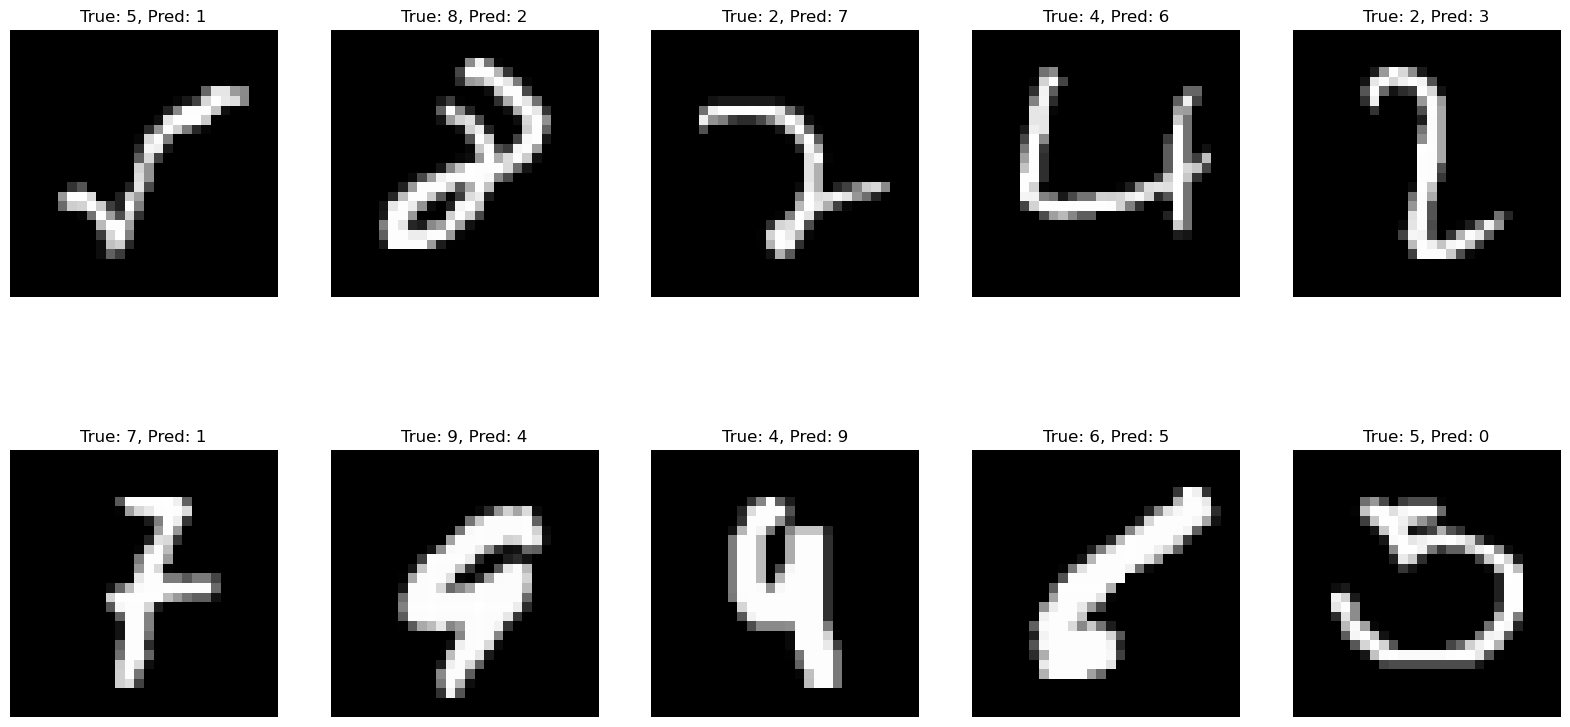

In [24]:
# Show the misclassified images
Z1, A1, Z2, A2, _ = forward_propagation(X_val.T, W1, b1, W2, b2)
predictions = np.argmax(A2, axis=0)
labels = np.argmax(y_val.T, axis=0)
misclassified_indices = np.where(predictions != labels)[0]

# Display the misclassified images
plt.figure(figsize=(20, 10))
for i, index in enumerate(misclassified_indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_val[index].reshape(28, 28), cmap='gray')
    plt.title(f"True: {labels[index]}, Pred: {predictions[index]}")
    plt.axis('off')

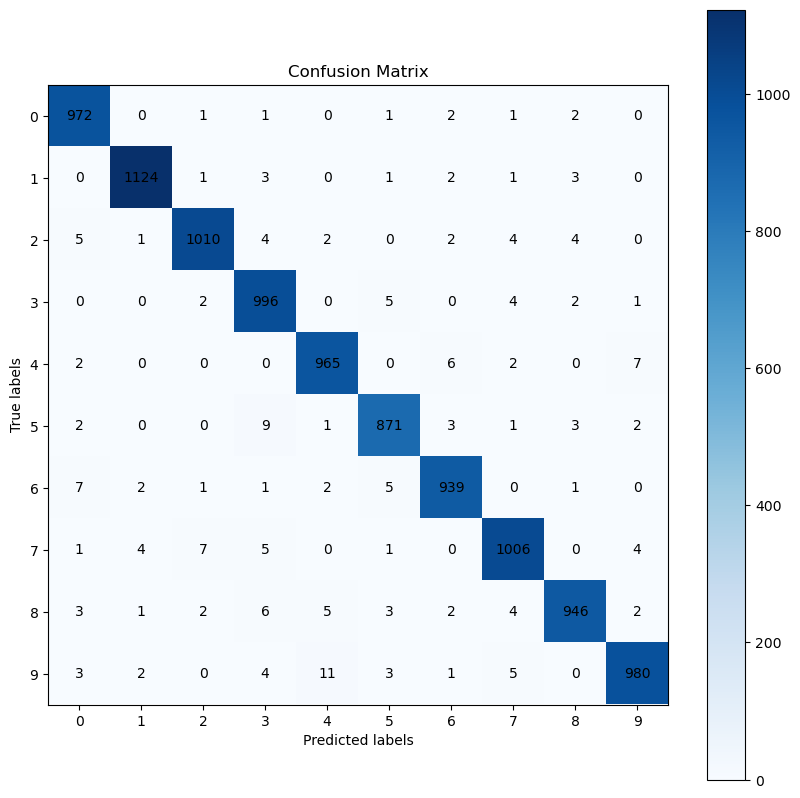

In [25]:
# Create a confusion matrix
from sklearn.metrics import confusion_matrix

# Compute the predictions on the test set
Z1, A1, Z2, A2, _ = forward_propagation(X_test.T, W1, b1, W2, b2, keep_prob=1.0)

# Compute the confusion matrix
predictions = np.argmax(A2, axis=0)
conf_matrix = confusion_matrix(np.argmax(y_test.T, axis=0), predictions)

# Display the confusion matrix
plt.figure(figsize=(10, 10))
plt.imshow(conf_matrix, cmap='Blues')
plt.colorbar()
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.xticks(np.arange(10))
plt.yticks(np.arange(10))
plt.title('Confusion Matrix')

# Annotate the confusion matrix with numbers
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        plt.text(j, i, conf_matrix[i, j], ha='center', va='center', color='black')

plt.show()


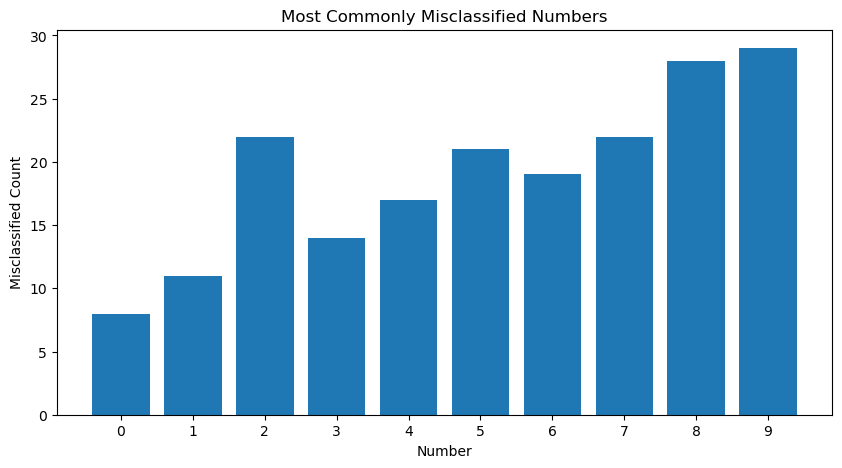

In [26]:
# Which numbers are most commonly misclassified?
misclassified_counts = np.sum(conf_matrix, axis=1) - np.diag(conf_matrix)

# Display the most commonly misclassified numbers
plt.figure(figsize=(10, 5))
plt.bar(np.arange(10), misclassified_counts)
plt.xlabel('Number')
plt.ylabel('Misclassified Count')
plt.title('Most Commonly Misclassified Numbers')
plt.xticks(np.arange(10))
plt.show()

In [27]:
# Find the numbers that each digit is most commonly misclassified as

def most_commonly_misclassified_as(conf_matrix, digit):
    conf_matrix[digit, digit] = -1  # Temporarily set the diagonal element to a value that can't be the max
    misclassified_as = np.argmax(conf_matrix[digit, :])
    conf_matrix[digit, digit] = np.sum(conf_matrix[digit, :])  # Restore the diagonal element
    return misclassified_as

# List of digits
digits = list(range(10))

# Find the misclassifications
for digit in digits:
    misclassified_as = most_commonly_misclassified_as(conf_matrix, digit)
    print(f"Number {digit} is most commonly misclassified as: {misclassified_as}")


Number 0 is most commonly misclassified as: 6
Number 1 is most commonly misclassified as: 3
Number 2 is most commonly misclassified as: 0
Number 3 is most commonly misclassified as: 5
Number 4 is most commonly misclassified as: 9
Number 5 is most commonly misclassified as: 3
Number 6 is most commonly misclassified as: 0
Number 7 is most commonly misclassified as: 2
Number 8 is most commonly misclassified as: 3
Number 9 is most commonly misclassified as: 4


***
# Test the model on the test set

In [28]:
# Evaluate the model on the test set
test_accuracy = evaluate_model(X_test, y_test, W1, b1, W2, b2)

In [29]:
print(f"Test Accuracy: {test_accuracy}")

Test Accuracy: 0.9809


In [30]:
# Display a sample image

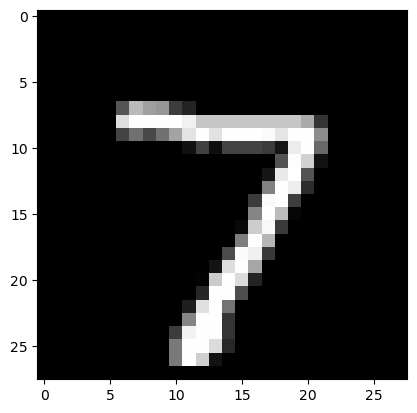

In [31]:
plt.imshow(X_test[0].reshape(28, 28), cmap='gray')

In [33]:
# Compute the prediction
Z1, A1, Z2, A2, _ = forward_propagation(X_test[0].reshape(-1, 784).T, W1, b1, W2, b2)

# Display the prediction
print(f"Prediction: {np.argmax(A2)}")

Prediction: 7


In [35]:
# Display the true label
print(f"True Label: {np.argmax(y_test[0])}")

True Label: 7


In [36]:
# Save the model

# Save the model
np.savez('mnist_model.npz', W1=W1, b1=b1, W2=W2, b2=b2)